In [1]:
from datasets import load_dataset_builder, load_dataset, get_dataset_split_names, load_from_disk
import matplotlib.pyplot as plt
import numpy as np
import json
from pathlib import Path
from huggingface_hub import hf_hub_download
import evaluate
from transformers import AutoImageProcessor
from torchvision.transforms import ColorJitter
import numpy as np
import torch
from torch import nn
from transformers import AutoModelForSemanticSegmentation, TrainingArguments, Trainer
from transformers import Mask2FormerForUniversalSegmentation

import warnings
warnings.filterwarnings("ignore")

c:\Users\dzky17\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\dzky17\AppData\Local\Programs\Python\Python313\Lib\site-packages\transformers\utils\hub.py:111: FutureWarning: Using `TRANSFORMERS_CACHE` is deprecated and will be removed in v5 of Transformers. Use `HF_HOME` instead.
  warnings.warn(


In [2]:
datasets = load_from_disk("./data/scene_parse_150/")
datasets

DatasetDict({
    test: Dataset({
        features: ['image', 'annotation', 'scene_category'],
        num_rows: 3352
    })
    validation: Dataset({
        features: ['image', 'annotation', 'scene_category'],
        num_rows: 2000
    })
    train: Dataset({
        features: ['image', 'annotation', 'scene_category'],
        num_rows: 20210
    })
})

In [3]:
ds = datasets['train'].select(range(500))
ds = ds.train_test_split(test_size=0.2, seed=42)
ds

DatasetDict({
    train: Dataset({
        features: ['image', 'annotation', 'scene_category'],
        num_rows: 400
    })
    test: Dataset({
        features: ['image', 'annotation', 'scene_category'],
        num_rows: 100
    })
})

In [4]:
index = np.random.randint(0, len(ds['train']))
ds['train'][index]

{'image': <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=768x512>,
 'annotation': <PIL.PngImagePlugin.PngImageFile image mode=L size=768x512>,
 'scene_category': 4}

In [5]:
def visualize_seg_mask(image, mask, title=None):
    fig, ax = plt.subplots(1, 1, figsize=(10, 10))
    ax.imshow(np.asarray(image))
    ax.imshow(np.asarray(mask), alpha=0.7)
    ax.set_title(title if title else "Segmentation Mask Overlay")
    
    plt.show()

visualize_seg_mask(ds['train'][index]['image'], ds['train'][index]['annotation'], title=ds['train'][index]['scene_category'])

KeyboardInterrupt: 

In [ ]:
repo_id = "huggingface/label-files"
filename = "ade20k-id2label.json"
id2label = json.loads(Path(hf_hub_download(repo_id, filename, repo_type="dataset")).read_text())
id2label = {int(k): v for k, v in id2label.items()}
label2id = {v: k for k, v in id2label.items()}
num_labels = len(id2label)

In [ ]:
train_ds = ds["train"]
test_ds = ds["test"]

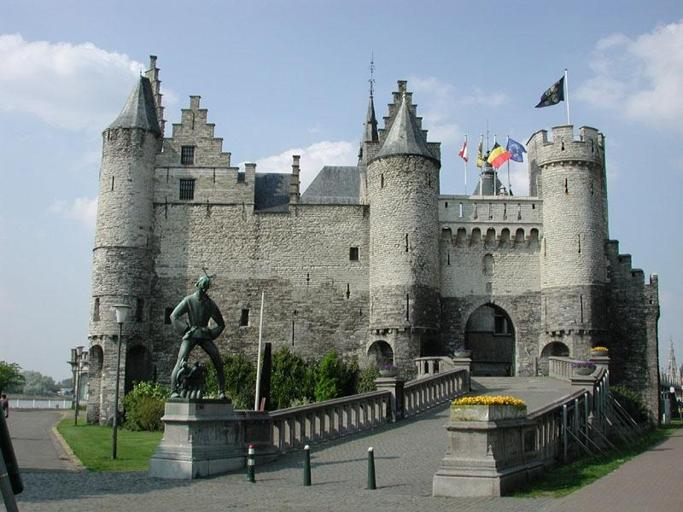

In [ ]:
train_ds[index]['image']

In [ ]:
checkpoint = "openmmlab/upernet-swin-tiny"
image_processor = AutoImageProcessor.from_pretrained(
    checkpoint,
    do_reduce_labels=True,
    size={"height": 256, "width": 256}   # resolusi lebih kecil dari default 512
)

Fetching 1 files: 100%|██████████| 1/1 [00:00<00:00, 11715.93it/s]
Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


In [ ]:
jitter = ColorJitter(brightness=0.25, contrast=0.25, saturation=0.25, hue=0.1)

In [ ]:
def train_transforms(example_batch):
    images = [jitter(x) for x in example_batch["image"]]
    labels = [x for x in example_batch["annotation"]]
    inputs = image_processor(images, labels)
    return inputs


def val_transforms(example_batch):
    images = [x for x in example_batch["image"]]
    labels = [x for x in example_batch["annotation"]]
    inputs = image_processor(images, labels)
    return inputs

In [ ]:
train_ds.set_transform(train_transforms)
test_ds.set_transform(val_transforms)

In [ ]:
metric = evaluate.load("mean_iou")

def compute_metrics(eval_pred):
    with torch.no_grad():
        logits, labels = eval_pred
        logits_tensor = torch.from_numpy(logits)
        logits_tensor = nn.functional.interpolate(
            logits_tensor,
            size=labels.shape[-2:],
            mode="bilinear",
            align_corners=False,
        ).argmax(dim=1)

        pred_labels = logits_tensor.detach().cpu().numpy()
        metrics = metric.compute(
            predictions=pred_labels,
            references=labels,
            num_labels=num_labels,
            ignore_index=255,
            reduce_labels=False,
        )
        for key, value in metrics.items():
            if isinstance(value, np.ndarray):
                metrics[key] = value.tolist()
        return metrics

In [ ]:
model = AutoModelForSemanticSegmentation.from_pretrained(checkpoint, id2label=id2label, label2id=label2id)

In [ ]:
type(train_ds), type(test_ds)

(datasets.arrow_dataset.Dataset, datasets.arrow_dataset.Dataset)

In [ ]:
training_args = TrainingArguments(
    output_dir="upernet-swin-tiny",
    learning_rate=6e-5,
    num_train_epochs=1,            # cukup 1 dulu untuk tes
    max_steps=500,                 # batasi step biar cepat
    per_device_train_batch_size=2, 
    per_device_eval_batch_size=2,
    gradient_accumulation_steps=1,
    save_total_limit=1,            # hanya simpan checkpoint terakhir
    eval_strategy="steps",
    save_strategy="steps",
    save_steps=500,                # simpan sekali di akhir
    eval_steps=500,                # evaluasi sekali di akhir
    logging_steps=50,
    eval_accumulation_steps=1,
    remove_unused_columns=False,
    push_to_hub=False,
    fp16=False,                    # matikan, karena di CPU/Windows sering bermasalah
    dataloader_num_workers=0       # aman di Windows, tidak error worker
)



trainer = Trainer(
    model=model, # model yang digunakan
    args=training_args, # argumen training
    train_dataset=train_ds, # dataset training
    eval_dataset=test_ds, # dataset evaluasi
    compute_metrics=compute_metrics, # fungsi untuk menghitung metriks
)


trainer.train()

Step,Training Loss,Validation Loss,Mean Iou,Mean Accuracy,Overall Accuracy,Per Category Iou,Per Category Accuracy
500,0.691000,0.759798,0.427998,0.574423,0.841212,"[0.6970431129701052, 0.8136196482773671, 0.9309547727571736, 0.786832750668351, 0.6998218077561823, 0.8211282739557494, 0.8112120524166986, 0.8051561281746489, 0.6005261019269018, 0.7492262239729882, 0.7122273016607835, 0.6155069420375543, 0.7479844501043681, 0.6164011963552897, 0.39274549694834515, 0.297742980871261, 0.4733654715275685, 0.5264614362846988, 0.6838884570152883, 0.29454720032342835, 0.6395273646464052, 0.8157626610728199, 0.6543331457512662, 0.3983007692101525, 0.6657088641908376, 0.4083758578215731, 0.9072206497085122, 0.6990672688884731, 0.5148209627697415, 0.7405964239700845, 0.13463670261009775, 0.8446373923564159, 0.4573439585777274, 0.5318088819352509, 0.4763887797595663, 0.69378513013133, 0.4468771606360913, 0.6579975495295559, 0.0, 0.7185585059819084, 0.003753625661149974, 0.41415065568770965, 0.5206928467539336, 0.4309207287050714, 0.836254324768873, 0.7799615116898005, 0.9077501017802287, 0.8128047318359843, 0.4542227481141843, 0.4818586887332909, 0.6520583578375932, 0.5134615384615384, 0.09527195165303946, 0.686124350666738, nan, 0.0, 0.8854158607350097, 0.6848464507467696, 0.0, 0.42874015748031497, 0.7688677083810659, nan, 0.4805194805194805, 0.466672119080723, 0.10029325513196481, 0.0, 0.5279247501469724, 0.2635435749803716, 0.0, 0.2384387936132466, 0.6448210922787194, 0.8008831794460056, 0.5259962049335863, 0.0, 0.3579967159277504, nan, nan, 0.0, 0.8708452880158906, nan, nan, 0.37756714060031593, 0.42054943725039334, 0.0, 0.0, 0.6130876747141042, 0.0, 0.10619156817780914, 0.5466591122728853, 0.3674101610904585, 0.7395646606914212, nan, 0.7623627095485838, 0.03322658126501201, 0.0, 0.018111254851228976, nan, 0.1432956606669457, 0.0, 0.6735395189003437, 0.5014834478450968, 0.33559577677224733, 0.4560352422907489, 0.0, 0.0, 0.6835641787696967, 0.0, 0.8740385485476427, nan, nan, 0.0, nan, 0.4732372111396405, nan, 0.9352495262160455, 0.0, nan, nan, 0.6282663669570104, 0.0, nan, 0.0, 0.9238833900750795, 0.45219435736677116, 0.3974158183241973, 0.0, nan, 0.3779928680590932, nan, 0.5152387808975282, 0.7985923458807265, 0.3878898444965685, 0.14239011986923356, 0.1866958664111689, 0.42704863424383743, 0.15527950310559005, 0.49587369931826336, 0.579556412729026, 0.20085015940488843, 0.0, nan, 0.0, 0.17258261933904528, 0.09335749546959946, 0.0, 0.0, 0.0, 0.0, 0.3826259946949602, 0.0]","[0.8048177506640506, 0.9102875568263218, 0.9481755042440909, 0.8731309223680779, 0.7978616845906272, 0.871341980332316, 0.8793672438556006, 0.9497625329815303, 0.703169018493245, 0.8439443762133038, 0.7789380418960825, 0.7326365857209882, 0.8575254948022437, 0.7935704851239115, 0.5403836963200656, 0.3681299198638394, 0.5843996429102812, 0.7081878794897672, 0.8661954052007069, 0.330901555580788, 0.8103538175046555, 0.9983862686129246, 0.7239473889018601, 0.5529262938572014, 0.851909668019565, 0.9253588516746412, 0.9530162355883308, 0.8342210173815978, 0.7525129982668978, 0.9995970734810731, 0.2015082956259427, 0.9429337570761744, 0.5996923566541134, 0.7703894835942676, 0.48054212570341603, 0.9668126809711188, 0.5218912614390813, 0.9155328251149925, 0.0, 0.7864899393165123, 0.007399932727884292, 0.4215427595840447, 0.5740859525336754, 0.5530489731437599, 0.9304556354916067, 0.9527834742159756, 0.9991241649014176, 0.9186918420814888, 0.9972937865338818, 0.8924255820807545, 0.8068714575607026, 0.8978905533476002, 0.10399689561505626, 0.9150121411226968, nan, nan, 0.9283686217246694, 0.7317554240631163, 0.0, 0.43484626647144947, 0.9696041606472118, nan, 0.6863406408094435, 0.57134274556924, 0.15154200638071605, nan, 0.6082637164145406, 0.5007458975634013, nan, 0.24227857228698474, 0.9558905639307649, 0.9347764970480742, 0.5784641068447413, nan, 0.8574687327932038, nan, nan, nan, 0.9990716046048411, nan, nan, 0.4579005747705959, 0.49353784973725323, 0.0, 0.0, 0.743451463790

TrainOutput(global_step=500, training_loss=0.9372777175903321, metrics={'train_runtime': 1461.9676, 'train_samples_per_second': 0.684, 'train_steps_per_second': 0.342, 'total_flos': 7.0710297624576e+16, 'train_loss': 0.9372777175903321, 'epoch': 2.5})

In [ ]:
model.save_pretrained("models/upernet-swin-tiny")